# Resultados executados — classificação e viés de comprimento

Este notebook é uma **apresentação dos resultados agregados** dos experimentos da versão 4. Ele não lê o corpus, não reexecuta o treinamento e não inclui notícias individuais. As métricas estão em `results/published_summary.json`, gerado após a execução dos experimentos no Fake.Br. As figuras e tabelas abaixo são reproduzíveis localmente com esse JSON.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

# Funciona tanto ao executar da raiz quanto da pasta notebooks/.
root = Path.cwd()
if not (root / 'results' / 'published_summary.json').is_file():
    root = root.parent
summary_path = root / 'results' / 'published_summary.json'
assert summary_path.is_file(), f'Resumo não encontrado: {summary_path}'
results = json.loads(summary_path.read_text(encoding='utf-8'))
print(f"Corpus: {results['n_rows']:,} notícias | seed={results['seed']}")

Corpus: 7,200 notícias | seed=42


## Comparação entre características

Validação cruzada aninhada com 5 folds externos e 3 internos, usando Regressão Logística e uma busca reduzida de hiperparâmetros. O desvio-padrão é calculado **entre folds**, não é intervalo de confiança.

In [2]:
labels = {'length_only': 'Só comprimento', 'emotion_only': 'Só emoções',
          'emotion_plus_length': 'Emoções + comprimento', 'means_only': 'Só médias'}
a = results['ablation']['summary']
rows = []
for key, label in labels.items():
    v = a[key]
    rows.append({'Atributos': label, 'F1': v['f1']['mean'], 'Desvio-padrão F1': v['f1']['std'],
                 'Acurácia': v['accuracy']['mean'], 'ROC AUC': v['roc_auc']['mean']})
table = pd.DataFrame(rows).set_index('Atributos')
print(table.round(4).to_string())

                           F1  Desvio-padrão F1  Acurácia  ROC AUC
Atributos                                                         
Só comprimento         0.9386            0.0066    0.9374   0.9804
Só emoções             0.6075            0.0132    0.6094   0.6399
Emoções + comprimento  0.9401            0.0058    0.9389   0.9807
Só médias              0.5460            0.0055    0.5490   0.5680


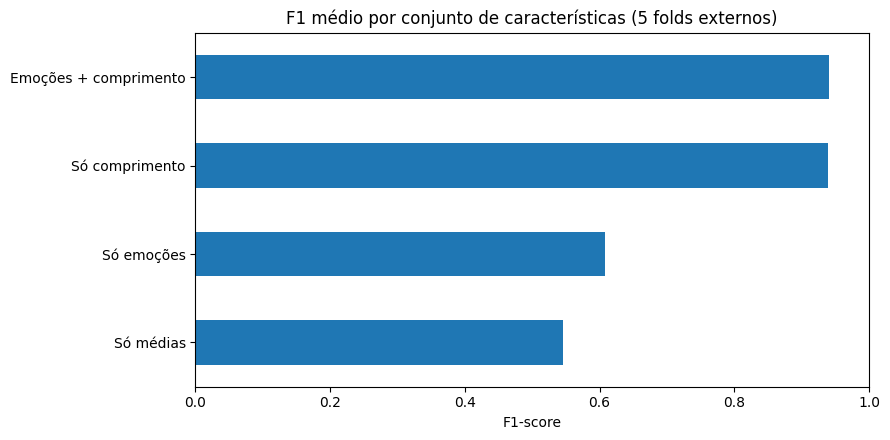

In [3]:
ax = table['F1'].sort_values().plot.barh(figsize=(9, 4.5), legend=False)
ax.set(title='F1 médio por conjunto de características (5 folds externos)', xlabel='F1-score', ylabel='')
ax.set_xlim(0, 1)
plt.tight_layout()
plt.show()

## Tamanho da notícia e classe

Uma diferença expressiva de comprimento pode funcionar como **atalho estatístico** para o classificador. As quantidades abaixo são medidas no texto pré-processado, com tokenização simplificada por espaços.

           n   mean  median    p25    p75     p90
fake  3600.0  107.9    92.0   67.8  130.0   179.0
true  3600.0  624.9   523.0  364.0  806.0  1123.1


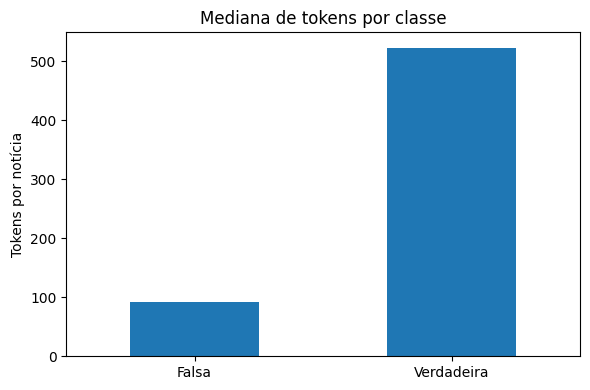

In [4]:
stats = pd.DataFrame(results['ablation']['length_audit']).T
print(stats[['n','mean','median','p25','p75','p90']].round(1).to_string())
ax = stats['median'].rename(index={'fake': 'Falsa', 'true': 'Verdadeira'}).plot.bar(rot=0, figsize=(6, 4))
ax.set(title='Mediana de tokens por classe', ylabel='Tokens por notícia', xlabel='')
plt.tight_layout()
plt.show()

## O ganho incremental das emoções é pequeno

A diferença de F1 entre as emoções combinadas com comprimento e apenas comprimento foi de aproximadamente **+0,0014** (0,14 ponto percentual), sem ganho consistente em todos os folds. Isso **não demonstra** que emoções causem a melhora. Também não garante desempenho em outros datasets.

In [5]:
diff = results['ablation']['paired_f1_differences']['emotion_plus_length_minus_length_only']
print(f"Diferença média de F1: {diff['mean']:+.4f} | DP entre folds: {diff['std']:.4f}")
print('Diferenças por fold:', [round(x, 4) for x in diff['by_fold']])

Diferença média de F1: +0.0014 | DP entre folds: 0.0042
Diferenças por fold: [-0.001, 0.0021, 0.0034, -0.0042, 0.0069]


## Seleção automática dos modelos (experimento anterior)

No protocolo separado de seleção aninhada, **normalização B + Regressão Logística** foi escolhida em todos os cinco folds. A apresentação deste resultado não equivale a uma avaliação externa independente.

In [6]:
selection = results['nested_selection']['selection_counts']
print(pd.Series(selection, name='Número de folds').loc[lambda s: s > 0].to_string())

B/logistic_regression    5


## Limitações

- Os documentos do Fake.Br podem diferir em tamanho devido ao processo de coleta e construção do corpus.
- A validação foi feita dentro do corpus e não comprova generalização externa.
- Foram agrupadas duplicatas exatas; duplicatas próximas e artigos relacionados não foram completamente auditados.
- O experimento não prova causalidade nem valida o sistema como ferramenta de checagem de fatos.

Fonte do corpus: [Fake.Br Corpus](https://github.com/roneysco/Fake.br-Corpus). Léxico: [SenticNet](https://sentic.net/).